# Final testing and stress scenario

Evaluate fixed ARX, adaptive ARX, AR(2) and persistence on the eight reserved quarters, 2024Q3–2026Q2. Compare their accuracy on one graph, then project fixed-ARX baseline and stressed NPL over four quarters from 2026Q2.

Run from `notebooks/`. Inputs: the split CSVs from Notebook 3 and the fixed/adaptive validation artifacts from Notebook 5.

## Imports and configuration

In [1]:
from pathlib import Path
import hashlib
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from IPython.display import display
from statsmodels.tsa.arima.model import ARIMA

pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")

TRAIN_DATA_PATH = Path("../data/processed/train.csv")
EVALUATION_DATA_PATH = Path("../data/processed/test.csv")
FIXED_PROTOCOL_PATH = Path("../reports/diagnostics/05_validation_protocol.json")
ADAPTIVE_VALIDATION_PATH = Path("../reports/diagnostics/05_adaptive_validation.json")
DIAGNOSTIC_DIRECTORY = Path("../reports/diagnostics")
FINAL_TEST_PATH = DIAGNOSTIC_DIRECTORY / "06_final_test_results.json"
EXPECTED_COLUMNS = ["quarter", "npl", "brent", "usdkzt"]
VALUE_COLUMNS = EXPECTED_COLUMNS[1:]
QUARTER_FREQUENCY = "Q-DEC"
TRAIN_END = pd.Period("2021Q4", freq=QUARTER_FREQUENCY)
VALIDATION_START = pd.Period("2022Q1", freq=QUARTER_FREQUENCY)
VALIDATION_END = pd.Period("2024Q2", freq=QUARTER_FREQUENCY)
TEST_START = pd.Period("2024Q3", freq=QUARTER_FREQUENCY)
TEST_END = pd.Period("2026Q2", freq=QUARTER_FREQUENCY)
MAIN_MODEL_NAME = "ARX2_oil2_fx4"
TARGET_COLUMN = "npl_change_pp"
MAX_FEATURE_LAG = 4
MODEL_COLUMNS = {
    "Fixed ARX": "fixed_arx_npl",
    "Adaptive ARX": "adaptive_arx_npl",
    "AR(2)": "ar2_npl",
    "Persistence": "persistence_npl",
}

# confirm that earlier notebooks have saved the required input artifacts
for input_path in [
    TRAIN_DATA_PATH,
    EVALUATION_DATA_PATH,
    FIXED_PROTOCOL_PATH,
    ADAPTIVE_VALIDATION_PATH,
]:
    assert input_path.exists(), f"Missing input artifact: {input_path}"

SCENARIO_ORIGIN = TEST_END
SCENARIO_HORIZON = 4
STRESS_BRENT_USD = 45.0
FX_DEPRECIATION = 0.30
SCENARIO_RESULTS_PATH = DIAGNOSTIC_DIRECTORY / "06_stress_scenario.json"

## Data and saved model checks

Load original levels and verify the 48/10/8 boundaries. Recover fixed ARX coefficients from the saved protocol and retain the adaptive update policy from validation. Neither validation artifact is modified.

In [2]:
def load_quarterly_data(data_path):
    # validate the original levels before assigning quarter labels
    data = pd.read_csv(data_path)
    assert data.columns.tolist() == EXPECTED_COLUMNS
    assert not data.isna().any().any()
    assert data["quarter"].str.fullmatch(r"\d{4}Q[1-4]").all()
    assert all(pd.api.types.is_numeric_dtype(data[column]) for column in VALUE_COLUMNS)
    assert np.isfinite(data[VALUE_COLUMNS].to_numpy()).all()
    assert data["npl"].between(0, 100).all()
    assert data[["brent", "usdkzt"]].gt(0).all().all()

    index = pd.PeriodIndex(data["quarter"], freq=QUARTER_FREQUENCY)
    assert index.is_unique and index.is_monotonic_increasing
    assert index.equals(pd.period_range(index.min(), index.max(), freq=QUARTER_FREQUENCY))
    data = data.drop(columns="quarter")
    data.index = index.rename("quarter")
    return data


train_data = load_quarterly_data(TRAIN_DATA_PATH)
evaluation_data = load_quarterly_data(EVALUATION_DATA_PATH)
validation_data = evaluation_data.loc[VALIDATION_START:VALIDATION_END].copy()
test_data = evaluation_data.loc[TEST_START:TEST_END].copy()
full_data = pd.concat([train_data, evaluation_data])

assert train_data.index.equals(pd.period_range("2010Q1", TRAIN_END, freq=QUARTER_FREQUENCY))
assert validation_data.index.equals(
    pd.period_range(VALIDATION_START, VALIDATION_END, freq=QUARTER_FREQUENCY)
)
assert test_data.index.equals(pd.period_range(TEST_START, TEST_END, freq=QUARTER_FREQUENCY))
assert [len(train_data), len(validation_data), len(test_data)] == [48, 10, 8]
assert full_data.index.equals(pd.period_range("2010Q1", TEST_END, freq=QUARTER_FREQUENCY))
assert train_data.index.intersection(evaluation_data.index).empty
assert validation_data.index.intersection(test_data.index).empty

fixed_protocol = json.loads(FIXED_PROTOCOL_PATH.read_text(encoding="utf-8"))
adaptive_validation = json.loads(ADAPTIVE_VALIDATION_PATH.read_text(encoding="utf-8"))
fixed_protocol_hash = hashlib.sha256(FIXED_PROTOCOL_PATH.read_bytes()).hexdigest()
adaptive_validation_hash = hashlib.sha256(ADAPTIVE_VALIDATION_PATH.read_bytes()).hexdigest()

assert fixed_protocol["model"] == adaptive_validation["fixed_model"] == MAIN_MODEL_NAME
assert fixed_protocol["training_input_sha256"] == hashlib.sha256(
    TRAIN_DATA_PATH.read_bytes()
).hexdigest()
assert adaptive_validation["fixed_protocol_sha256"] == fixed_protocol_hash
assert fixed_protocol["training_fit"]["end"] == str(TRAIN_END)
assert fixed_protocol["training_fit"]["observations"] == 43
assert fixed_protocol["forecast_rules"]["horizon_quarters"] == 1
assert adaptive_validation["forecast_rules"]["horizon_quarters"] == 1
assert adaptive_validation["forecast_rules"]["refit_policy"] == (
    "expanding-window OLS at each origin through target minus one"
)
assert adaptive_validation["validation_end"] == str(VALIDATION_END)

selected_predictors = fixed_protocol["predictors"]
assert selected_predictors == adaptive_validation["predictors"] == [
    "npl_change_pp_lag_1",
    "npl_change_pp_lag_2",
    "brent_log_change_pct_lag_2",
    "usdkzt_log_change_pct_lag_4",
]
fixed_parameters = pd.Series(
    fixed_protocol["training_fit"]["coefficients"], name="coefficient"
)
assert fixed_parameters.index.tolist() == ["const"] + selected_predictors
assert np.isfinite(fixed_parameters.to_numpy()).all()
fixed_parameters_snapshot = fixed_parameters.copy()

display(train_data.head())
train_data.info()
display(pd.DataFrame([
    {
        "sample": name,
        "start": str(data.index.min()),
        "end": str(data.index.max()),
        "quarters": len(data),
    }
    for name, data in [
        ("Training", train_data), ("Validation", validation_data), ("Final test", test_data)
    ]
]).set_index("sample"))

<class 'pandas.core.frame.DataFrame'>
PeriodIndex: 48 entries, 2010Q1 to 2021Q4
Freq: Q-DEC
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   npl     48 non-null     float64
 1   brent   48 non-null     float64
 2   usdkzt  48 non-null     float64
dtypes: float64(3)
memory usage: 2.5 KB


,npl,brent,usdkzt
quarter,,,
2010Q1,24.9600,76.6700,147.7000
2010Q2,25.2500,78.8500,146.8100
2010Q3,25.8300,76.6800,147.4100
2010Q4,23.7500,87.0300,147.4900
2011Q1,25.2700,105.3700,146.4200


,start,end,quarters
sample,,,
Training,2010Q1,2021Q4,48
Validation,2022Q1,2024Q2,10
Final test,2024Q3,2026Q2,8


## Past-only forecasting inputs

Reuse NPL first differences and oil/FX log differences ×100, with no additional scaling or rounding. Build each fit and forecast input from history ending at $t-1$. Assume previous-quarter observations are available; publication delays and data revisions are not simulated.

In [3]:
def make_changes(history):
    # retain quarterly timing while calculating backward-looking changes
    assert history.index.is_unique and history.index.is_monotonic_increasing
    changes = pd.DataFrame({
        TARGET_COLUMN: history["npl"].diff(),
        "brent_log_change_pct": np.log(history["brent"]).diff() * 100,
        "usdkzt_log_change_pct": np.log(history["usdkzt"]).diff() * 100,
    }, index=history.index)
    assert changes.iloc[0].isna().all()
    assert changes.iloc[1:].notna().all().all()
    assert np.isfinite(changes.iloc[1:].to_numpy()).all()
    return changes


def make_arx_training_sample(history):
    # construct the same selected lagged equation on the available history
    changes = make_changes(history)
    sample = changes[[TARGET_COLUMN]].copy()
    for feature in selected_predictors:
        source_column, lag_text = feature.rsplit("_lag_", 1)
        sample[feature] = changes[source_column].shift(int(lag_text))
    sample = sample.dropna().copy()

    assert sample.index.equals(history.index[MAX_FEATURE_LAG + 1:])
    assert sample.index.max() == history.index.max()
    assert np.isfinite(sample.to_numpy()).all()
    return sample


def make_arx_forecast_inputs(history, target_quarter):
    # recover every predictor from its exact earlier source quarter
    origin_quarter = target_quarter - 1
    assert history.index.max() == origin_quarter
    assert (history.index <= origin_quarter).all()
    changes = make_changes(history)
    values = {}
    for feature in selected_predictors:
        source_column, lag_text = feature.rsplit("_lag_", 1)
        source_quarter = target_quarter - int(lag_text)
        assert source_quarter <= origin_quarter
        values[feature] = changes.loc[source_quarter, source_column]

    inputs = pd.DataFrame(
        [values],
        index=pd.PeriodIndex([target_quarter], freq=QUARTER_FREQUENCY),
    ).rename_axis("quarter")
    inputs = sm.add_constant(inputs, has_constant="add")
    assert inputs.columns.tolist() == fixed_parameters.index.tolist()
    assert np.isfinite(inputs.to_numpy()).all()
    return inputs


# independently verify the preserved coefficients against the original training sample
initial_arx_sample = make_arx_training_sample(train_data)
initial_design = sm.add_constant(
    initial_arx_sample[selected_predictors], has_constant="add"
)
assert len(initial_arx_sample) == 43
assert str(initial_arx_sample.index.min()) == fixed_protocol["training_fit"]["start"]
np.testing.assert_allclose(
    np.linalg.lstsq(
        initial_design.to_numpy(), initial_arx_sample[TARGET_COLUMN].to_numpy(), rcond=None
    )[0],
    fixed_parameters.to_numpy(),
    rtol=0,
    atol=1e-12,
)

## AR(2) and persistence benchmarks

Fit ARIMA(2,0,0) with a constant mean on the 47 pre-2022 NPL changes, matching Notebook 3. The series is already differenced; no MA terms or additional differencing are added. Keep AR coefficients fixed, while updating its observed history with [`append(refit=False)`](https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMAResults.append.html).

Persistence requires no estimation: next quarter's NPL equals the latest observed level. AR(2)'s 47-row fit and ARX's 43-row fit have different training sample lengths; compare their forecasts on the same test quarters, not their information criteria.

In [4]:
# estimate the npl-only benchmark before any test forecast is generated
ar2_target = make_changes(train_data)[TARGET_COLUMN].dropna().copy()
assert ar2_target.index.equals(train_data.index[1:])
assert len(ar2_target) == 47 and ar2_target.index.max() == TRAIN_END

with warnings.catch_warnings(record=True) as recorded:
    warnings.simplefilter("always")
    ar2_result = ARIMA(
        ar2_target,
        order=(2, 0, 0),
        trend="c",
        enforce_stationarity=True,
        enforce_invertibility=True,
    ).fit(method_kwargs={"maxiter": 1000})

assert ar2_result.mle_retvals.get("converged", False)
assert int(ar2_result.nobs) == 47
assert np.isfinite(ar2_result.params.to_numpy()).all()
assert np.abs(ar2_result.arroots).min() > 1
ar2_parameters = ar2_result.params.copy()

display(ar2_parameters.rename("estimate").to_frame())
fit_warnings = pd.DataFrame([
    {"category": warning.category.__name__, "message": str(warning.message)}
    for warning in recorded
], columns=["category", "message"])
if fit_warnings.empty:
    print("No AR(2) fit warnings recorded.")
else:
    display(fit_warnings)

No AR(2) fit warnings recorded.


,estimate
const,-0.4479
ar.L1,0.0561
ar.L2,0.3080
sigma2,5.5331


## Rolling final-test forecasts

Generate eight forecasts from origins 2024Q2–2026Q1, targeting 2024Q3–2026Q2. All models use the same observed history at each origin.

- Fixed ARX uses the saved pre-2022 coefficients.
- Adaptive ARX refits through each origin, beginning with 53 complete rows through 2024Q2 and ending with 60 through 2026Q1.
- AR(2) updates its state from actual past NPL changes without re-estimating coefficients.
- Persistence uses the last observed NPL level.

The adaptive policy may learn from earlier test outcomes before subsequent forecasts, as specified during validation; it never sees its own target outcome. It remains supplementary to the strictly pre-2022-fitted main model. No clipping, bias correction or test-driven tuning is applied.

In [5]:
forecast_rows = []
audit_rows = []
adaptive_coefficient_rows = []
ar2_state = ar2_result

# forecast before attaching the target quarter's actual npl
for step, target_quarter in enumerate(test_data.index):
    origin_quarter = target_quarter - 1
    observed_history = full_data.loc[:origin_quarter].copy()
    assert observed_history.index.max() == origin_quarter
    assert (observed_history.index < target_quarter).all()
    forecast_inputs = make_arx_forecast_inputs(observed_history, target_quarter)
    latest_npl = float(observed_history["npl"].iloc[-1])

    fixed_change = float(
        forecast_inputs.to_numpy()[0] @ fixed_parameters.to_numpy()
    )

    adaptive_sample = make_arx_training_sample(observed_history)
    adaptive_design = sm.add_constant(
        adaptive_sample[selected_predictors], has_constant="add"
    )
    assert adaptive_sample.index.max() == origin_quarter
    assert (adaptive_sample.index < target_quarter).all()
    assert len(adaptive_sample) == 53 + step
    assert adaptive_design.columns.equals(forecast_inputs.columns)
    assert np.linalg.matrix_rank(adaptive_design.to_numpy()) == adaptive_design.shape[1]
    adaptive_result = sm.OLS(
        adaptive_sample[TARGET_COLUMN], adaptive_design, missing="raise"
    ).fit()
    assert np.isfinite(adaptive_result.params.to_numpy()).all()
    adaptive_change = float(adaptive_result.predict(forecast_inputs).iloc[0])

    # update ar history with observed changes while preserving its fitted parameters
    observed_changes = make_changes(observed_history)[TARGET_COLUMN].dropna()
    state_end = ar2_state.model.data.row_labels.max()
    new_observations = observed_changes.loc[observed_changes.index > state_end]
    if not new_observations.empty:
        assert new_observations.index.min() == state_end + 1
        ar2_state = ar2_state.append(new_observations, refit=False)
    assert ar2_state.model.data.row_labels.max() == origin_quarter
    pd.testing.assert_series_equal(ar2_state.params, ar2_parameters, check_exact=True)
    ar2_forecast = ar2_state.forecast(steps=1)
    assert ar2_forecast.index[0] == target_quarter
    ar2_change = float(ar2_forecast.iloc[0])

    # verify the ar forecast against its constant-mean representation
    ar2_mean = float(ar2_parameters["const"])
    direct_ar2_change = (
        ar2_mean
        + ar2_parameters["ar.L1"] * (observed_changes.loc[origin_quarter] - ar2_mean)
        + ar2_parameters["ar.L2"] * (observed_changes.loc[origin_quarter - 1] - ar2_mean)
    )
    np.testing.assert_allclose(ar2_change, direct_ar2_change, rtol=0, atol=1e-10)

    forecast_rows.append({
        "quarter": target_quarter,
        "forecast_origin_quarter": origin_quarter,
        "latest_observed_npl": latest_npl,
        "fixed_arx_npl": latest_npl + fixed_change,
        "adaptive_arx_npl": latest_npl + adaptive_change,
        "ar2_npl": latest_npl + ar2_change,
        "persistence_npl": latest_npl,
    })
    audit_rows.append({
        "quarter": target_quarter,
        "forecast_origin_quarter": origin_quarter,
        "fixed_arx_fit_end": str(TRAIN_END),
        "fixed_arx_fit_observations": 43,
        "adaptive_fit_end": origin_quarter,
        "adaptive_fit_observations": int(adaptive_result.nobs),
        "ar2_parameter_fit_end": str(TRAIN_END),
        "ar2_parameter_fit_observations": 47,
        "ar2_observed_changes": int(ar2_state.nobs),
    })
    adaptive_coefficient_rows.append({
        "quarter": target_quarter,
        **adaptive_result.params.to_dict(),
    })

test_forecasts = pd.DataFrame(forecast_rows).set_index("quarter")
forecast_audit = pd.DataFrame(audit_rows).set_index("quarter")
adaptive_test_coefficients = pd.DataFrame(
    adaptive_coefficient_rows
).set_index("quarter")

assert test_forecasts.index.equals(test_data.index)
assert len(test_forecasts) == 8
assert test_forecasts.index.intersection(validation_data.index).empty
assert (test_forecasts["forecast_origin_quarter"] == test_forecasts.index - 1).all()
assert forecast_audit["adaptive_fit_observations"].tolist() == list(range(53, 61))
assert forecast_audit["ar2_observed_changes"].tolist() == list(range(57, 65))
assert (forecast_audit["adaptive_fit_end"] == test_data.index - 1).all()
assert np.isfinite(test_forecasts.select_dtypes(include=np.number).to_numpy()).all()
assert np.isfinite(adaptive_test_coefficients.to_numpy()).all()
np.testing.assert_allclose(
    test_forecasts["latest_observed_npl"],
    full_data["npl"].shift(1).loc[test_data.index],
    rtol=0,
    atol=0,
)
pd.testing.assert_series_equal(
    fixed_parameters, fixed_parameters_snapshot, check_exact=True
)
pd.testing.assert_series_equal(ar2_result.params, ar2_parameters, check_exact=True)

display(forecast_audit)

,forecast_origin_quarter,fixed_arx_fit_end,fixed_arx_fit_observations,adaptive_fit_end,adaptive_fit_observations,ar2_parameter_fit_end,ar2_parameter_fit_observations,ar2_observed_changes
quarter,,,,,,,,
2024Q3,2024Q2,2021Q4,43,2024Q2,53,2021Q4,47,57
2024Q4,2024Q3,2021Q4,43,2024Q3,54,2021Q4,47,58
2025Q1,2024Q4,2021Q4,43,2024Q4,55,2021Q4,47,59
2025Q2,2025Q1,2021Q4,43,2025Q1,56,2021Q4,47,60
2025Q3,2025Q2,2021Q4,43,2025Q2,57,2021Q4,47,61
2025Q4,2025Q3,2021Q4,43,2025Q3,58,2021Q4,47,62
2026Q1,2025Q4,2021Q4,43,2025Q4,59,2021Q4,47,63
2026Q2,2026Q1,2021Q4,43,2026Q1,60,2021Q4,47,64


## Forecast accuracy and comparison

Attach actual test outcomes after generating forecasts. Define error as actual minus forecast: positive values indicate underprediction. Compare MAE, RMSE and mean error in NPL percentage points on the same eight targets. The ranking reports this test period only and does not trigger model changes.

In [6]:
test_results = test_forecasts.join(
    test_data["npl"].rename("actual_npl"),
    how="left",
    validate="one_to_one",
)
assert test_results.index.equals(test_data.index)
assert not test_results.isna().any().any()

test_errors = pd.DataFrame(index=test_data.index)
metric_rows = []
for model_name, forecast_column in MODEL_COLUMNS.items():
    errors = test_results["actual_npl"] - test_results[forecast_column]
    test_errors[model_name] = errors
    metric_rows.append({
        "model": model_name,
        "observations": len(errors),
        "mae_pp": errors.abs().mean(),
        "rmse_pp": np.sqrt(np.mean(errors.to_numpy() ** 2)),
        "mean_error_pp": errors.mean(),
        "underpredicted_quarters": int(errors.gt(0).sum()),
        "overpredicted_quarters": int(errors.lt(0).sum()),
        "exact_quarters": int(errors.eq(0).sum()),
    })

test_metrics = pd.DataFrame(metric_rows).set_index("model").sort_values("mae_pp")
assert test_errors.shape == (8, 4)
assert test_metrics["observations"].eq(8).all()
assert np.isfinite(test_errors.to_numpy()).all()
assert np.isfinite(test_metrics.to_numpy()).all()
assert (test_metrics["rmse_pp"] >= test_metrics["mae_pp"] - 1e-12).all()
assert test_metrics[[
    "underpredicted_quarters", "overpredicted_quarters", "exact_quarters"
]].sum(axis=1).eq(8).all()
np.testing.assert_allclose(
    test_results["persistence_npl"],
    test_results["latest_observed_npl"],
    rtol=0,
    atol=0,
)

display(test_results[["actual_npl"] + list(MODEL_COLUMNS.values())])
display(test_metrics)
display(test_errors)

,actual_npl,fixed_arx_npl,adaptive_arx_npl,ar2_npl,persistence_npl
quarter,,,,,
2024Q3,3.2200,2.8095,2.8461,2.8618,3.0900
2024Q4,3.0500,3.0869,3.1076,2.9487,3.2200
2025Q1,3.3600,2.6997,2.7536,2.7957,3.0500
2025Q2,3.3700,2.7910,2.8789,3.0403,3.3600
2025Q3,3.5200,2.9487,3.0167,3.1812,3.3700
2025Q4,3.6300,2.3884,2.5590,3.2467,3.5200
2026Q1,3.9700,3.4576,3.5342,3.3976,3.6300
2026Q2,4.1200,3.3308,3.4915,3.7382,3.9700


,observations,mae_pp,rmse_pp,mean_error_pp,underpredicted_quarters,overpredicted_quarters,exact_quarters
model,,,,,,,
Persistence,8,0.1713,0.1983,0.1288,7,1,0
AR(2),8,0.3787,0.4033,0.3787,8,0,0
Adaptive ARX,8,0.5209,0.5849,0.5065,7,1,0
Fixed ARX,8,0.6001,0.6796,0.5909,7,1,0


,Fixed ARX,Adaptive ARX,AR(2),Persistence
quarter,,,,
2024Q3,0.4105,0.3739,0.3582,0.1300
2024Q4,-0.0369,-0.0576,0.1013,-0.1700
2025Q1,0.6603,0.6064,0.5643,0.3100
2025Q2,0.5790,0.4911,0.3297,0.0100
2025Q3,0.5713,0.5033,0.3388,0.1500
2025Q4,1.2416,1.0710,0.3833,0.1100
2026Q1,0.5124,0.4358,0.5724,0.3400
2026Q2,0.7892,0.6285,0.3818,0.1500


### Unified forecast graph

Display actual NPL and the four model forecasts on one shared axis, in original percentage units. The graph covers only final-test targets; all lines are rolling one-quarter-ahead forecasts. No image file is exported.

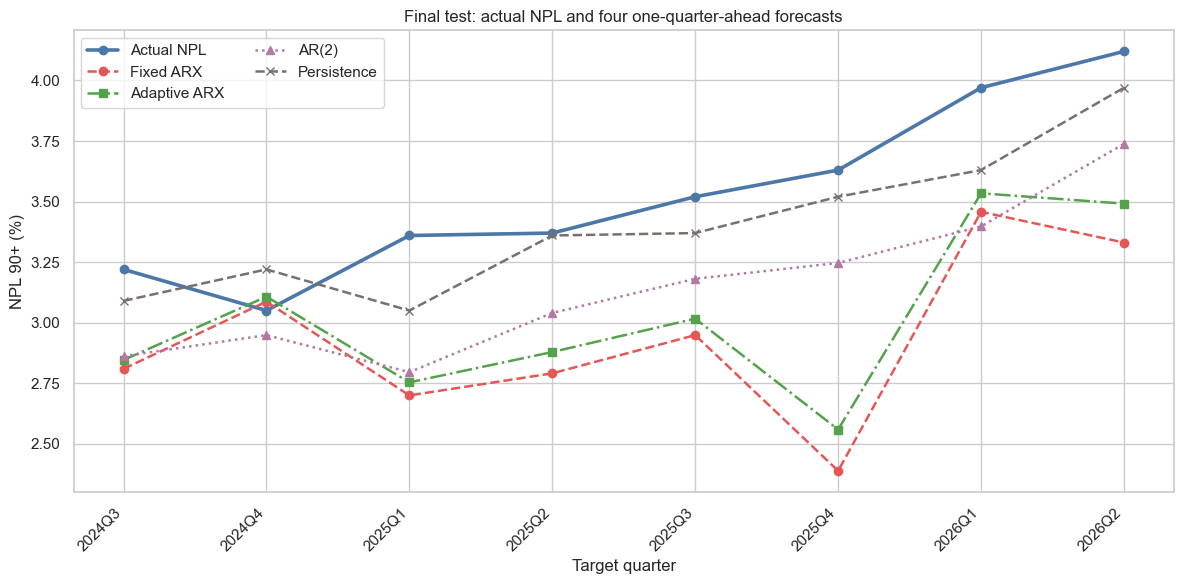

In [7]:
quarter_positions = np.arange(len(test_results))
figure, axis = plt.subplots(figsize=(12, 6))

# show all four forecasts and actual npl on the same scale
plot_specifications = [
    ("actual_npl", "Actual NPL", "#4C78A8", "-", "o", 2.6),
    ("fixed_arx_npl", "Fixed ARX", "#E45756", "--", "o", 1.8),
    ("adaptive_arx_npl", "Adaptive ARX", "#54A24B", "-.", "s", 1.8),
    ("ar2_npl", "AR(2)", "#B279A2", ":", "^", 1.8),
    ("persistence_npl", "Persistence", "#79706E", "--", "x", 1.8),
]
for column, label, color, linestyle, marker, linewidth in plot_specifications:
    axis.plot(
        quarter_positions,
        test_results[column],
        color=color,
        linestyle=linestyle,
        marker=marker,
        linewidth=linewidth,
        label=label,
    )

assert len(axis.lines) == 5
axis.set(
    title="Final test: actual NPL and four one-quarter-ahead forecasts",
    xlabel="Target quarter",
    ylabel="NPL 90+ (%)",
)
axis.set_xticks(quarter_positions)
axis.set_xticklabels(test_results.index.astype(str), rotation=45, ha="right")
axis.legend(loc="upper left", ncol=2)
figure.tight_layout()
plt.show()
plt.close(figure)

## Save final-test results

Save forecasts, error measures, origin-level fit checks and adaptive coefficient history in `reports/diagnostics/06_final_test_results.json`. This testing-stage snapshot remains unchanged when the separate scenario is added. Preserve both validation artifacts; changed results require review before replacement.

In [8]:
def frame_to_records(frame):
    # serialize full-precision results and period labels without rounding
    records = []
    for row in frame.reset_index().to_dict(orient="records"):
        record = {}
        for key, value in row.items():
            if isinstance(value, pd.Period):
                record[key] = str(value)
            elif isinstance(value, np.generic):
                record[key] = value.item()
            else:
                record[key] = value
        records.append(record)
    return records


final_test_artifact = {
    "status": "final_testing_completed_scenario_pending",
    "test_start": str(TEST_START),
    "test_end": str(TEST_END),
    "target_quarters": len(test_results),
    "training_input_sha256": hashlib.sha256(TRAIN_DATA_PATH.read_bytes()).hexdigest(),
    "evaluation_input_sha256": hashlib.sha256(EVALUATION_DATA_PATH.read_bytes()).hexdigest(),
    "fixed_validation_protocol_sha256": fixed_protocol_hash,
    "adaptive_validation_sha256": adaptive_validation_hash,
    "model_columns": MODEL_COLUMNS,
    "arx_predictors": selected_predictors,
    "fixed_arx_coefficients": {
        name: float(value) for name, value in fixed_parameters.items()
    },
    "ar2_training_fit": {
        "order": [2, 0, 0],
        "trend": "constant mean",
        "start": str(ar2_target.index.min()),
        "end": str(TRAIN_END),
        "observations": len(ar2_target),
        "parameters": {name: float(value) for name, value in ar2_parameters.items()},
    },
    "forecast_rules": {
        "horizon_quarters": 1,
        "origin": "target quarter minus one",
        "fixed_arx": "preserved pre-2022 coefficients; actual past observations update inputs",
        "adaptive_arx": "expanding-window OLS through each origin; includes earlier validation/test outcomes",
        "adaptive_initial_test_fit_end": str(VALIDATION_END),
        "ar2": "fixed pre-2022 parameters; append observed changes with refit=False",
        "persistence": "latest observed NPL level",
        "availability_assumption": "all previous-quarter data observed; no release-vintage simulation",
        "error_definition": "actual NPL minus forecast",
        "metric_units": "NPL percentage points",
        "prediction_clipping": False,
        "bias_correction": False,
        "test_driven_tuning": False,
    },
    "forecasts": frame_to_records(test_results),
    "metrics": frame_to_records(test_metrics),
    "errors": frame_to_records(test_errors),
    "forecast_audit": frame_to_records(forecast_audit),
    "adaptive_coefficients": frame_to_records(adaptive_test_coefficients),
    "final_testing_performed": True,
    "benchmarks_evaluated": ["AR(2)", "Persistence"],
    "stress_scenario_performed": False,
    "final_assignment_interpretation_written": False,
}

assert len(final_test_artifact["forecasts"]) == 8
assert len(final_test_artifact["metrics"]) == 4
assert hashlib.sha256(FIXED_PROTOCOL_PATH.read_bytes()).hexdigest() == fixed_protocol_hash
assert hashlib.sha256(
    ADAPTIVE_VALIDATION_PATH.read_bytes()
).hexdigest() == adaptive_validation_hash
pd.testing.assert_series_equal(
    fixed_parameters, fixed_parameters_snapshot, check_exact=True
)
pd.testing.assert_series_equal(ar2_result.params, ar2_parameters, check_exact=True)

DIAGNOSTIC_DIRECTORY.mkdir(parents=True, exist_ok=True)
if FINAL_TEST_PATH.exists():
    saved_test_artifact = json.loads(FINAL_TEST_PATH.read_text(encoding="utf-8"))
    assert saved_test_artifact == final_test_artifact, (
        "Saved final-test results differ. Review before replacing the artifact."
    )
else:
    FINAL_TEST_PATH.write_text(
        json.dumps(final_test_artifact, indent=2, allow_nan=False) + "\n",
        encoding="utf-8",
    )
assert json.loads(FINAL_TEST_PATH.read_text(encoding="utf-8")) == final_test_artifact
print(f"Saved final-test results: {FINAL_TEST_PATH}")
print("The stress scenario and final assignment interpretation remain pending.")

Saved final-test results: ../reports/diagnostics/06_final_test_results.json
The stress scenario and final assignment interpretation remain pending.


## Four-quarter stress scenario

Use the fixed ARX coefficients estimated through 2021Q4. The forecast origin is 2026Q2, with observed NPL of 4.12%, Brent of USD 97.05 and USD/KZT of 476.00. Forecast 2026Q3–2027Q2 from this common starting state.

Baseline oil and FX stay at their origin levels. The stress path starts in 2026Q3: Brent falls to USD 45 and USD/KZT rises by 30% to 618.80, then both levels remain constant. Here, depreciation means a 30% increase in KZT per USD; it is not applied repeatedly each quarter.

Future NPL is predicted recursively, not replaced by future actuals. Keep coefficients fixed, retain full precision and do not clip forecasts. This is a conditional model exercise, not an observed or identified causal effect.

In [9]:
# define future macro levels without altering historical observations
observed_scenario_history = full_data.loc[:SCENARIO_ORIGIN].copy()
assert observed_scenario_history.index.max() == SCENARIO_ORIGIN
origin_values = observed_scenario_history.iloc[-1].copy()
scenario_quarters = pd.period_range(
    SCENARIO_ORIGIN + 1, periods=SCENARIO_HORIZON, freq=QUARTER_FREQUENCY
).rename("quarter")

scenario_macro_paths = {
    "Baseline": pd.DataFrame({
        "brent": float(origin_values["brent"]),
        "usdkzt": float(origin_values["usdkzt"]),
    }, index=scenario_quarters),
    "Stress": pd.DataFrame({
        "brent": STRESS_BRENT_USD,
        "usdkzt": float(origin_values["usdkzt"]) * (1 + FX_DEPRECIATION),
    }, index=scenario_quarters),
}
scenario_assumptions = pd.DataFrame([
    {
        "path": name,
        "future_brent_usd": float(path["brent"].iloc[0]),
        "future_usdkzt": float(path["usdkzt"].iloc[0]),
        "initial_brent_log_change_pct": (
            100 * np.log(path["brent"].iloc[0] / origin_values["brent"])
        ),
        "initial_usdkzt_log_change_pct": (
            100 * np.log(path["usdkzt"].iloc[0] / origin_values["usdkzt"])
        ),
    }
    for name, path in scenario_macro_paths.items()
]).set_index("path")

assert SCENARIO_ORIGIN == full_data.index.max()
assert scenario_quarters.min() > full_data.index.max()
assert len(scenario_quarters) == 4
for path in scenario_macro_paths.values():
    assert path.index.equals(scenario_quarters)
    assert path.gt(0).all().all()
    assert np.isfinite(path.to_numpy()).all()
    assert path.nunique().eq(1).all()
np.testing.assert_allclose(
    scenario_macro_paths["Stress"]["usdkzt"],
    float(origin_values["usdkzt"]) * 1.30,
    rtol=0,
    atol=1e-12,
)

display(origin_values.rename("origin_value").to_frame())
display(scenario_assumptions)

,origin_value
npl,4.1200
brent,97.0500
usdkzt,476.0000


,future_brent_usd,future_usdkzt,initial_brent_log_change_pct,initial_usdkzt_log_change_pct
path,,,,
Baseline,97.0500,476.0000,0.0000,0.0000
Stress,45.0000,618.8000,-76.8564,26.2364


### Recursive NPL projections

Predict the next NPL change and add it to the preceding level. Append that predicted NPL and the hypothetical macro levels to the path's history before forecasting the next quarter. No future actual NPL is used.

In [10]:
scenario_forecast_rows = []
scenario_parameter_snapshot = fixed_parameters.copy()

# forecast both paths recursively with the saved fixed coefficients
for path_name, macro_path in scenario_macro_paths.items():
    scenario_history = observed_scenario_history.copy()
    for horizon, target_quarter in enumerate(scenario_quarters, start=1):
        assert scenario_history.index.max() == target_quarter - 1
        forecast_inputs = make_arx_forecast_inputs(scenario_history, target_quarter)
        predicted_change = float(
            forecast_inputs.to_numpy()[0] @ fixed_parameters.to_numpy()
        )
        previous_npl = float(scenario_history["npl"].iloc[-1])
        predicted_npl = previous_npl + predicted_change

        scenario_forecast_rows.append({
            "path": path_name,
            "quarter": target_quarter,
            "scenario_origin_quarter": SCENARIO_ORIGIN,
            "horizon_quarters": horizon,
            "previous_npl_source": "observed origin" if horizon == 1 else "previous prediction",
            "previous_npl": previous_npl,
            "predicted_change_pp": predicted_change,
            "predicted_npl": predicted_npl,
            "brent_usd": float(macro_path.loc[target_quarter, "brent"]),
            "usdkzt": float(macro_path.loc[target_quarter, "usdkzt"]),
            "oil_source_quarter": target_quarter - 2,
            "fx_source_quarter": target_quarter - 4,
            "oil_predictor_log_change_pct": float(
                forecast_inputs["brent_log_change_pct_lag_2"].iloc[0]
            ),
            "fx_predictor_log_change_pct": float(
                forecast_inputs["usdkzt_log_change_pct_lag_4"].iloc[0]
            ),
            "npl_within_0_100": bool(0 <= predicted_npl <= 100),
        })

        # carry predicted npl forward rather than inserting future outcomes
        future_row = pd.DataFrame({
            "npl": [predicted_npl],
            "brent": [float(macro_path.loc[target_quarter, "brent"])],
            "usdkzt": [float(macro_path.loc[target_quarter, "usdkzt"])],
        }, index=pd.PeriodIndex(
            [target_quarter], freq=QUARTER_FREQUENCY
        )).rename_axis("quarter")
        scenario_history = pd.concat([scenario_history, future_row])
        pd.testing.assert_frame_equal(
            scenario_history.loc[observed_scenario_history.index],
            observed_scenario_history,
            check_exact=True,
        )

scenario_forecasts = pd.DataFrame(scenario_forecast_rows).set_index(["path", "quarter"])
assert len(scenario_forecasts) == 8
assert scenario_forecasts.index.is_unique
assert np.isfinite(
    scenario_forecasts.select_dtypes(include=np.number).to_numpy()
).all()
for path_name in scenario_macro_paths:
    path_forecasts = scenario_forecasts.loc[path_name]
    assert path_forecasts.index.equals(scenario_quarters)
    assert path_forecasts["horizon_quarters"].tolist() == [1, 2, 3, 4]
    assert path_forecasts["previous_npl_source"].tolist() == [
        "observed origin", "previous prediction", "previous prediction", "previous prediction"
    ]
    np.testing.assert_allclose(
        path_forecasts["previous_npl"].iloc[1:],
        path_forecasts["predicted_npl"].iloc[:-1],
        rtol=0,
        atol=0,
    )
pd.testing.assert_series_equal(
    fixed_parameters, scenario_parameter_snapshot, check_exact=True
)
pd.testing.assert_frame_equal(
    observed_scenario_history, full_data.loc[:SCENARIO_ORIGIN], check_exact=True
)

### Scenario table and one-year result

Show projected NPL and the stress-minus-baseline difference in percentage points. Check the 0–100% bounds without clipping. The initial macro changes occur once; flat future levels imply zero changes thereafter.

In [11]:
baseline_projection = scenario_forecasts.loc["Baseline"]
stress_projection = scenario_forecasts.loc["Stress"]
scenario_table = pd.DataFrame({
    "baseline_npl_pct": baseline_projection["predicted_npl"],
    "stress_npl_pct": stress_projection["predicted_npl"],
    "stress_minus_baseline_pp": (
        stress_projection["predicted_npl"] - baseline_projection["predicted_npl"]
    ),
    "baseline_within_0_100": baseline_projection["npl_within_0_100"],
    "stress_within_0_100": stress_projection["npl_within_0_100"],
}, index=scenario_quarters)

year_ahead_quarter = scenario_quarters[-1]
scenario_year_ahead = pd.DataFrame([{
    "quarter": str(year_ahead_quarter),
    "origin_npl_pct": float(origin_values["npl"]),
    "baseline_npl_pct": float(scenario_table.loc[year_ahead_quarter, "baseline_npl_pct"]),
    "stress_npl_pct": float(scenario_table.loc[year_ahead_quarter, "stress_npl_pct"]),
    "stress_minus_baseline_pp": float(
        scenario_table.loc[year_ahead_quarter, "stress_minus_baseline_pp"]
    ),
    "stress_minus_origin_pp": float(
        scenario_table.loc[year_ahead_quarter, "stress_npl_pct"] - origin_values["npl"]
    ),
}]).set_index("quarter")

# verify new shock timing and the recursive oil contribution
oil_first_effect_quarter = scenario_quarters[0] + 2
fx_first_effect_quarter = scenario_quarters[0] + 4
assert oil_first_effect_quarter == SCENARIO_ORIGIN + 3
assert fx_first_effect_quarter == SCENARIO_ORIGIN + 5
assert fx_first_effect_quarter > scenario_quarters.max()
assert (stress_projection["fx_source_quarter"] <= SCENARIO_ORIGIN).all()
np.testing.assert_allclose(
    baseline_projection["fx_predictor_log_change_pct"],
    stress_projection["fx_predictor_log_change_pct"],
    rtol=0,
    atol=0,
)
np.testing.assert_allclose(
    scenario_table["stress_minus_baseline_pp"].iloc[:2],
    np.zeros(2),
    rtol=0,
    atol=1e-12,
)
initial_oil_shock = float(
    scenario_assumptions.loc["Stress", "initial_brent_log_change_pct"]
)
oil_contribution_at_first_entry = (
    fixed_parameters["brent_log_change_pct_lag_2"] * initial_oil_shock
)
np.testing.assert_allclose(
    scenario_table.loc[oil_first_effect_quarter, "stress_minus_baseline_pp"],
    oil_contribution_at_first_entry,
    rtol=0,
    atol=1e-12,
)
np.testing.assert_allclose(
    scenario_table.loc[year_ahead_quarter, "stress_minus_baseline_pp"],
    oil_contribution_at_first_entry * (1 + fixed_parameters["npl_change_pp_lag_1"]),
    rtol=0,
    atol=1e-12,
)

training_oil_predictor = initial_arx_sample["brent_log_change_pct_lag_2"]
scenario_extrapolation = pd.DataFrame([{
    "predictor": "brent_log_change_pct_lag_2",
    "training_min": float(training_oil_predictor.min()),
    "training_max": float(training_oil_predictor.max()),
    "stress_initial_change": initial_oil_shock,
    "outside_training_range": bool(
        initial_oil_shock < training_oil_predictor.min()
        or initial_oil_shock > training_oil_predictor.max()
    ),
}]).set_index("predictor")

display(scenario_table)
display(scenario_year_ahead)
display(scenario_extrapolation)
if not scenario_table[["baseline_within_0_100", "stress_within_0_100"]].all().all():
    print("Warning: invalid NPL levels were predicted; no clipping was applied.")

,baseline_npl_pct,stress_npl_pct,stress_minus_baseline_pp,baseline_within_0_100,stress_within_0_100
quarter,,,,,
2026Q3,4.9551,4.9551,0.0000,True,True
2026Q4,6.1846,6.1846,0.0000,True,True
2027Q1,6.5800,2.2067,-4.3733,True,True
2027Q2,7.0873,2.8745,-4.2127,True,True


,origin_npl_pct,baseline_npl_pct,stress_npl_pct,stress_minus_baseline_pp,stress_minus_origin_pp
quarter,,,,,
2027Q2,4.1200,7.0873,2.8745,-4.2127,-1.2455


,training_min,training_max,stress_initial_change,outside_training_range
predictor,,,,
brent_log_change_pct_lag_2,-42.7392,29.8813,-76.8564,True


### Baseline and stress plot

Include the observed origin as the common starting point. Mark 2027Q1, when the new oil shock first enters; the new FX shock first enters in 2027Q3, beyond this horizon.

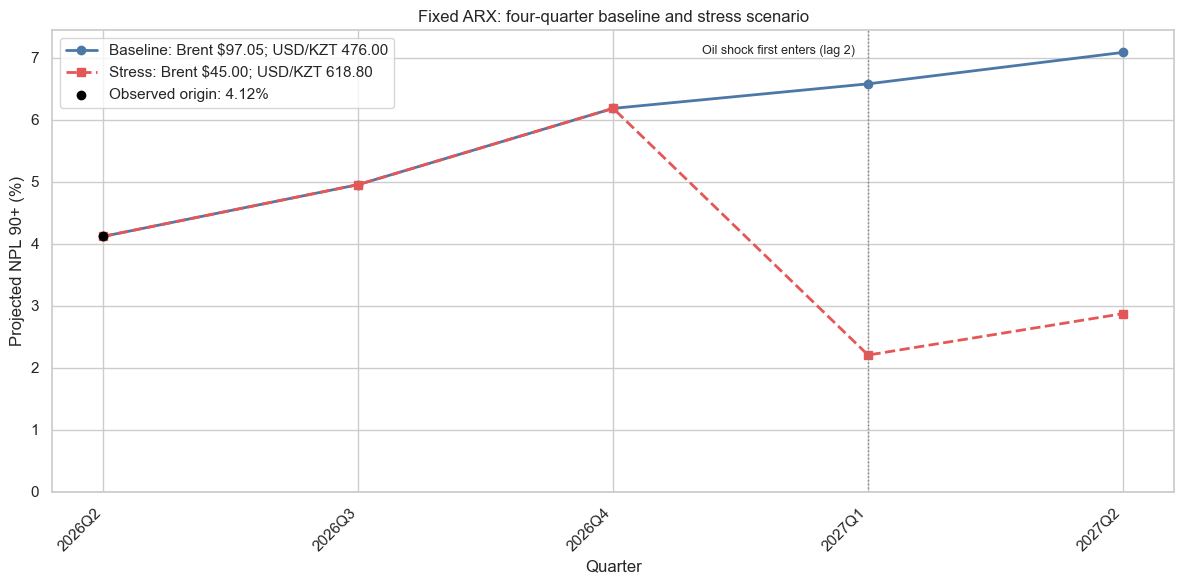

In [12]:
scenario_plot_quarters = pd.PeriodIndex(
    [SCENARIO_ORIGIN] + list(scenario_quarters), freq=QUARTER_FREQUENCY
)
scenario_plot_data = pd.DataFrame({
    "Baseline": [float(origin_values["npl"])] + scenario_table["baseline_npl_pct"].tolist(),
    "Stress": [float(origin_values["npl"])] + scenario_table["stress_npl_pct"].tolist(),
}, index=scenario_plot_quarters)
scenario_positions = np.arange(len(scenario_plot_data))
figure, axis = plt.subplots(figsize=(12, 6))

# display the raw model projections without hiding their counterintuitive direction
for name, color, linestyle, marker in [
    ("Baseline", "#4C78A8", "-", "o"),
    ("Stress", "#E45756", "--", "s"),
]:
    macro_levels = scenario_macro_paths[name].iloc[0]
    axis.plot(
        scenario_positions, scenario_plot_data[name],
        color=color, linestyle=linestyle, marker=marker, linewidth=2,
        label=f"{name}: Brent $" + f"{macro_levels['brent']:.2f}; USD/KZT {macro_levels['usdkzt']:.2f}",
    )
axis.scatter(
    [0], [float(origin_values["npl"])],
    color="black", zorder=5,
    label=f"Observed origin: {origin_values['npl']:.2f}%",
)
oil_effect_position = int(scenario_plot_quarters.get_loc(oil_first_effect_quarter))
axis.axvline(oil_effect_position, color="gray", linestyle=":", linewidth=1)
axis.text(
    oil_effect_position - 0.05, 0.97, "Oil shock first enters (lag 2)",
    transform=axis.get_xaxis_transform(), ha="right", va="top", fontsize=9,
)
axis.axhline(0, color="black", linewidth=0.8)
axis.set_ylim(bottom=min(0, float(scenario_plot_data.min().min()) - 0.2))
axis.set(
    title="Fixed ARX: four-quarter baseline and stress scenario",
    xlabel="Quarter",
    ylabel="Projected NPL 90+ (%)",
)
axis.set_xticks(scenario_positions)
axis.set_xticklabels(scenario_plot_quarters.astype(str), rotation=45, ha="right")
axis.legend(loc="upper left")
figure.tight_layout()
plt.show()
plt.close(figure)

### Save scenario results

Save assumptions, recursive projections, lag timing, range checks and the one-year comparison in `reports/diagnostics/06_stress_scenario.json`. Preserve the fixed model and all historical evaluation artifacts.

In [13]:
scenario_artifact = {
    "status": "stress_scenario_completed_final_interpretation_pending",
    "model": MAIN_MODEL_NAME,
    "parameter_policy": "fixed coefficients estimated through 2021Q4; no scenario refitting",
    "fixed_protocol_sha256": fixed_protocol_hash,
    "scenario_origin": str(SCENARIO_ORIGIN),
    "origin_values": {name: float(value) for name, value in origin_values.items()},
    "horizon_quarters": SCENARIO_HORIZON,
    "shock_start": str(scenario_quarters[0]),
    "year_ahead_quarter": str(year_ahead_quarter),
    "assumptions": {
        "baseline": "oil and USD/KZT stay at observed origin levels",
        "stress_brent_usd": STRESS_BRENT_USD,
        "stress_usdkzt_multiplier": 1 + FX_DEPRECIATION,
        "depreciation_definition": "30% increase in KZT per USD",
        "duration": "new macro levels persist throughout all four future quarters",
        "shock_changes": "one initial log change; subsequent changes zero",
        "npl_history": "actual history through origin, then recursive predictions only",
        "prediction_clipping": False,
        "future_actuals_used": False,
        "uncertainty_intervals": "not computed",
    },
    "coefficients": {name: float(value) for name, value in fixed_parameters.items()},
    "macro_assumptions": frame_to_records(scenario_assumptions),
    "recursive_forecasts": frame_to_records(scenario_forecasts),
    "quarterly_comparison": frame_to_records(scenario_table),
    "year_ahead_comparison": frame_to_records(scenario_year_ahead),
    "oil_first_new_shock_effect_quarter": str(oil_first_effect_quarter),
    "fx_first_new_shock_effect_quarter": str(fx_first_effect_quarter),
    "new_fx_shock_enters_within_horizon": False,
    "oil_extrapolation_check": frame_to_records(scenario_extrapolation),
    "all_npl_predictions_within_0_100": bool(
        scenario_forecasts["npl_within_0_100"].all()
    ),
    "causal_economic_interpretation_supported": False,
    "stress_scenario_performed": True,
    "final_assignment_interpretation_written": False,
}

assert len(scenario_artifact["recursive_forecasts"]) == 8
assert len(scenario_artifact["quarterly_comparison"]) == 4
assert hashlib.sha256(FIXED_PROTOCOL_PATH.read_bytes()).hexdigest() == fixed_protocol_hash
assert hashlib.sha256(
    ADAPTIVE_VALIDATION_PATH.read_bytes()
).hexdigest() == adaptive_validation_hash
assert json.loads(FINAL_TEST_PATH.read_text(encoding="utf-8")) == final_test_artifact
pd.testing.assert_series_equal(
    fixed_parameters, fixed_parameters_snapshot, check_exact=True
)
pd.testing.assert_frame_equal(
    observed_scenario_history, full_data.loc[:SCENARIO_ORIGIN], check_exact=True
)

# save this hypothetical exercise separately from historical test results
if SCENARIO_RESULTS_PATH.exists():
    saved_scenario_artifact = json.loads(
        SCENARIO_RESULTS_PATH.read_text(encoding="utf-8")
    )
    assert saved_scenario_artifact == scenario_artifact, (
        "Saved scenario results differ. Review before replacing the artifact."
    )
else:
    SCENARIO_RESULTS_PATH.write_text(
        json.dumps(scenario_artifact, indent=2, allow_nan=False) + "\n",
        encoding="utf-8",
    )
assert json.loads(
    SCENARIO_RESULTS_PATH.read_text(encoding="utf-8")
) == scenario_artifact
print(f"Saved stress-scenario results: {SCENARIO_RESULTS_PATH}")
print("The final plain-language assignment interpretation remains pending.")

Saved stress-scenario results: ../reports/diagnostics/06_stress_scenario.json
The final plain-language assignment interpretation remains pending.


## Conclusion

The final test and stress scenario are complete. Persistence has the lowest test errors; adaptive updating improves on fixed ARX but neither beats the benchmarks. Fixed ARX projects one-year NPL of 2.87% under stress versus 7.09% under the baseline. The counterintuitive decline, delayed FX response and oil-shock extrapolation limit economic interpretation; these projections are conditional model outputs, not reliable causal effects.